# Does the flood-tolerance gene SUB1A switch off cell division in rice shoots during submergence?
**Riddhika D** · Plant Meristem Climate Resilience project (v2.1, real data)

**Background.** Flooding kills rice when plants try to escape by elongating fast and run out of energy. The **SUB1A** gene (in flood-tolerant "Sub1" rice varieties now grown across India) makes plants **wait quietly** underwater instead ("quiescence"). Its effects on elongation, hormones and anaerobic metabolism are well studied (Xu 2006; Fukao 2006; Jung 2010). Whether SUB1A also **shuts down the cell-division programme** in the shoot was not analysed in the original microarray paper (Jung et al. 2010 reported no cell-cycle or meristem gene analysis).

**Data.** NCBI GEO **GSE18930**: Affymetrix rice arrays of aerial tissue from near-identical lines **M202** (flood-intolerant) and **M202(Sub1)** (tolerant), with and without submergence.

### Decided before looking at results
| | |
|---|---|
| **Main question** | Is the submergence response of **cell-division genes** (cyclins, CDKs, histone H4, MCM, PCNA…) *more negative* in M202(Sub1) than in M202? |
| **Known-biology check** | **Cell-expansion genes** (expansins, XTHs) should also be held down more in Sub1, because SUB1A restricts elongation |
| **Label check** | **Anaerobic genes** (alcohol dehydrogenase, pyruvate decarboxylase) must rise under submergence in **both** lines; otherwise stop |
| **Measure** | Per gene: Δ = (submerged − control in Sub1) − (submerged − control in M202), on log2 expression |
| **Test** | Mean Δ of the gene set vs **10,000 random gene sets** matched for expression level |
| **Positive result** | Cell-division set Δ < 0 with empirical p < 0.05 |

Run: **Runtime → Run all** (about 3–5 minutes). Copy the **SEND THIS TO CLAUDE** box at the end.

In [1]:
!pip -q install GEOparse 2>/dev/null | tail -1
import re, os, logging, warnings
import numpy as np, pandas as pd
import GEOparse
warnings.filterwarnings('ignore'); logging.getLogger('GEOparse').setLevel(logging.ERROR)
REPORT = []
def note(s): print(s); REPORT.append(str(s))
RNG = np.random.default_rng(2026); N_PERM = 10000
GSE_ID = 'GSE18930'
gse = GEOparse.get_GEO(geo=GSE_ID, destdir='geo', silent=True)
note(f'{GSE_ID}: {len(gse.gsms)} samples, platforms: {list(gse.gpls)}')

GSE18930: 8 samples, platforms: ['GPL2025']


## 1. Sample design (read from GEO, not assumed)

In [2]:
rows = []
for name, g in gse.gsms.items():
    m = g.metadata
    rows.append(dict(gsm=name, title=' '.join(m.get('title', [])),
                     text=' | '.join(m.get('title', []) + m.get('source_name_ch1', []) + m.get('characteristics_ch1', []))))
meta = pd.DataFrame(rows).set_index('gsm')
t = meta.title.str.lower()
# v2: read genotype and day from the sample TITLE only (e.g. "M202(Sub1) at day 1, biological rep2");
# the characteristics mention Sub1 and plant age for every sample, which fooled v1
meta['genotype'] = np.where(t.str.contains(r'\(sub1\)|sub1\b'), 'Sub1', 'M202')
meta['days'] = t.str.extract(r'day\s*(\d+(?:\.\d+)?)', expand=False).astype(float)
meta['treat'] = np.where(meta.days == 0, 'control', np.where(meta.days > 0, 'submerged', 'unknown'))
pd.set_option('display.max_colwidth', 120)
display(meta[['title', 'genotype', 'days', 'treat']])
note('design: ' + '; '.join(f'{gt}/{tr}: {n}' for (gt, tr), n in meta.groupby(['genotype', 'treat']).size().items()))
if (meta.treat == 'submerged').any() and meta.loc[meta.treat == 'submerged', 'days'].notna().any():
    note('submergence durations (days): ' + str(sorted(meta.loc[meta.treat == 'submerged', 'days'].dropna().unique())))

,title,genotype,days,treat
gsm,,,,
GSM468793,"M202 at day 0, biological rep1",M202,0.0,control
GSM468794,"M202 at day 0, biological rep2",M202,0.0,control
GSM468795,"M202 at day 1, biological rep1",M202,1.0,submerged
GSM468796,"M202 at day 1, biological rep2",M202,1.0,submerged
GSM468797,"M202(Sub1) at day 0, biological rep1",Sub1,0.0,control
GSM468798,"M202(Sub1) at day 0, biological rep2",Sub1,0.0,control
GSM468799,"M202(Sub1) at day 1, biological rep1",Sub1,1.0,submerged
GSM468800,"M202(Sub1) at day 1, biological rep2",Sub1,1.0,submerged


design: M202/control: 2; M202/submerged: 2; Sub1/control: 2; Sub1/submerged: 2
submergence durations (days): [np.float64(1.0)]


## 2. Expression matrix and gene annotation

In [3]:
X = gse.pivot_samples('VALUE').astype(float)
X = X[meta.index.intersection(X.columns)]
if np.nanmax(X.values) > 100: X = np.log2(X.clip(lower=1))
X = X.dropna()
gpl = list(gse.gpls.values())[0].table
idc = 'ID'
title_col = next((c for c in gpl.columns if c.lower() in ('gene title', 'gene_title', 'description', 'gene description')), None)
sym_col = next((c for c in gpl.columns if c.lower() in ('gene symbol', 'gene_symbol', 'symbol')), None)
go_col = next((c for c in gpl.columns if 'biological process' in c.lower()), None)
note(f'probes: {len(X)}; annotation columns: {list(gpl.columns)}')
ann = gpl.set_index(idc).reindex(X.index)
text_cols = [c for c in gpl.columns if any(k in c.lower() for k in ('title', 'description', 'symbol', 'def'))]
TITLE = ann[text_cols].fillna('').astype(str).agg(' | '.join, axis=1).str.lower() if text_cols else pd.Series('', index=X.index)
GO = ann[go_col].fillna('').astype(str).str.lower() if go_col else pd.Series('', index=X.index)
# keep one probe per gene symbol (highest mean expression); unannotated probes are kept as they are
if sym_col:
    sym = ann[sym_col].fillna('').astype(str)
    key = np.where(sym != '', sym, X.index)
    best = X.mean(1).groupby(key).idxmax()
    X = X.loc[best.values]; TITLE = TITLE.loc[X.index]; GO = GO.loc[X.index]
X = X[X.mean(1) > X.mean(1).quantile(0.2)]          # drop the lowest-expressed 20 %
TITLE = TITLE.loc[X.index]; GO = GO.loc[X.index]
note(f'genes after collapsing and filtering: {len(X)}')

probes: 57381; annotation columns: ['ID', 'GB_ACC', 'SPOT_ID', 'Species Scientific Name', 'Annotation Date', 'Sequence Type', 'Sequence Source', 'Representative Public ID', 'Target Description', 'Gene Title', 'Gene Symbol', 'ENTREZ_GENE_ID', 'RefSeq Transcript ID', 'Gene Ontology Biological Process', 'Gene Ontology Cellular Component', 'Gene Ontology Molecular Function']
genes after collapsing and filtering: 40461


## 3. Gene sets (defined by name, before testing)

In [4]:
SETS = {
 'cell_division': r'\bcyclin\b|cyclin-dependent kinase|cyclin dependent kinase|histone h4|minichromosome maintenance|\bmcm\d|proliferating cell nuclear antigen|\bpcna\b|kinesin.*(phragmoplast|cell plate)|\baurora\b|cdc20|cell division control protein|e2f',
 'cell_expansion': r'expansin|xyloglucan endotransglu|endo-1,4-beta-glucanase|cellulose synthase',
 'anaerobic': r'alcohol dehydrogenase|pyruvate decarboxylase|lactate dehydrogenase|sucrose synthase',
}
GS = {k: [g for g in X.index if re.search(p, TITLE[g])] for k, p in SETS.items()}
if go_col:
    GS['cell_cycle_GO'] = [g for g in X.index if 'cell cycle' in GO[g] or 'cell division' in GO[g] or 'dna replication' in GO[g]]
# anaerobic label-check genes: also accept GO terms for fermentation / hypoxia
GS['anaerobic'] = sorted(set(GS['anaerobic']) | {g for g in X.index if 'fermentation' in GO[g] or 'response to hypoxia' in GO[g]})
note('gene set sizes: ' + ', '.join(f'{k}={len(v)}' for k, v in GS.items()))
note('example annotation text: ' + ' || '.join(TITLE[X.index[:3]].str[:120]))

gene set sizes: cell_division=45, cell_expansion=43, anaerobic=42, cell_cycle_GO=168
example annotation text: e. coli /gen=biob /db_xref=gb:j04423.1 /note=sif corresponding to nucleotides 2755-3052 of gb:j04423.1 /def=e.coli 7,8-d || e. coli /gen=biob /db_xref=gb:j04423.1 /note=sif corresponding to nucleotides 2032-2305 of gb:j04423.1 /def=e.coli 7,8-d || e. coli /gen=biob /db_xref=gb:j04423.1 /note=sif corresponding to nucleotides 2482-2739 of gb:j04423.1 /def=e.coli 7,8-d


## 4. Submergence response in each line, and the Sub1 − M202 difference

In [5]:
def grp(gt, tr):
    s = meta[(meta.genotype == gt) & (meta.treat == tr)]
    if tr == 'submerged' and s.days.notna().any(): s = s[s.days == s.days.max()]   # longest submergence
    return [c for c in s.index if c in X.columns]
G = {(gt, tr): grp(gt, tr) for gt in ['M202', 'Sub1'] for tr in ['control', 'submerged']}
note('samples used: ' + '; '.join(f'{k[0]}-{k[1]}={len(v)}' for k, v in G.items()))
assert all(len(v) > 0 for v in G.values()), 'could not find all four groups - send the design table above to Claude'
resp = {gt: X[G[(gt, 'submerged')]].mean(1) - X[G[(gt, 'control')]].mean(1) for gt in ['M202', 'Sub1']}
D = resp['Sub1'] - resp['M202']

# label check: anaerobic genes must go up in both lines
an = GS['anaerobic']
lab = {gt: resp[gt][an].mean() for gt in resp}
note(f'LABEL CHECK anaerobic genes (n={len(an)}): mean log2 change M202 {lab["M202"]:+.2f}, Sub1 {lab["Sub1"]:+.2f} -> '
     f'{"PASS" if min(lab.values()) > 0 else "FAIL - do not interpret"}')

samples used: M202-control=2; M202-submerged=2; Sub1-control=2; Sub1-submerged=2
LABEL CHECK anaerobic genes (n=42): mean log2 change M202 +1.09, Sub1 +1.36 -> PASS


## 5. Test against expression-matched random gene sets

In [6]:
bins = pd.qcut(X.mean(1).rank(method='first'), 10, labels=False)
by_bin = {b: np.array(X.index[bins == b]) for b in range(10)}
def null_mean(vec, genes):
    out = np.zeros(N_PERM)
    for g in genes:
        out += vec[RNG.choice(by_bin[bins[g]], N_PERM)].values
    return out / len(genes)
def test(vec, genes):
    obs = vec[genes].mean(); nul = null_mean(vec, genes)
    p_low = (1 + (nul <= obs).sum()) / (1 + N_PERM); p_two = min(1, 2 * min(p_low, 1 - p_low + 1 / (1 + N_PERM)))
    return obs, nul.mean(), p_low, p_two
RES = []
for k, genes in GS.items():
    if len(genes) < 5: note(f'{k}: too few genes ({len(genes)})'); continue
    for label, vec in [('M202 response', resp['M202']), ('Sub1 response', resp['Sub1']), ('Sub1 minus M202', D)]:
        obs, nm, pl, p2 = test(vec, genes)
        RES.append(dict(set=k, n=len(genes), measure=label, mean_log2=obs, null_mean=nm, p_lower=pl, p_two_sided=p2))
R = pd.DataFrame(RES); R.to_csv('rice_sub1_set_tests.csv', index=False)
note('set tests (mean log2 change; p vs 10,000 matched random sets):\n' + R.round(4).to_string(index=False))
primary = 'cell_division' if len(GS['cell_division']) >= 20 else 'cell_cycle_GO'
note(f'primary set for the verdict: {primary} (name-based set used if it has >= 20 genes)')
cd = R[(R.set == primary) & (R.measure == 'Sub1 minus M202')]
if len(cd):
    r_ = cd.iloc[0]
    verdict = ('POSITIVE: Sub1 lowers cell-division genes more than M202' if r_.mean_log2 < 0 and r_.p_lower < 0.05 else
               'OPPOSITE: Sub1 keeps cell-division genes HIGHER than M202' if r_.mean_log2 > 0 and r_.p_two_sided < 0.05 else
               'NULL: no Sub1-specific effect on cell-division genes')
    note(f'PRE-REGISTERED VERDICT: {verdict} (delta {r_.mean_log2:+.3f}, p_lower {r_.p_lower:.4f}, two-sided {r_.p_two_sided:.4f})')

set tests (mean log2 change; p vs 10,000 matched random sets):
           set   n         measure  mean_log2  null_mean  p_lower  p_two_sided
 cell_division  45   M202 response    -0.0202     0.0456   0.3535       0.7069
 cell_division  45   Sub1 response     0.0725     0.0767   0.4966       0.9931
 cell_division  45 Sub1 minus M202     0.0927     0.0316   0.8349       0.3304
cell_expansion  43   M202 response    -0.2372     0.0091   0.0498       0.0996
cell_expansion  43   Sub1 response    -0.4304     0.0304   0.0029       0.0058
cell_expansion  43 Sub1 minus M202    -0.1933     0.0192   0.0027       0.0054
     anaerobic  42   M202 response     1.0902     0.0268   1.0000       0.0002
     anaerobic  42   Sub1 response     1.3582     0.0499   1.0000       0.0002
     anaerobic  42 Sub1 minus M202     0.2680     0.0249   0.9980       0.0042
 cell_cycle_GO 168   M202 response     0.0426     0.0318   0.5529       0.8943
 cell_cycle_GO 168   Sub1 response     0.0979     0.0634   0.6495   

## 6. Exploratory: individual cell-division genes

In [7]:
cg = GS[primary]
T = pd.DataFrame({'title': TITLE[cg].str[:80], 'M202_resp': resp['M202'][cg], 'Sub1_resp': resp['Sub1'][cg], 'Sub1_minus_M202': D[cg]}).sort_values('Sub1_minus_M202')
T.to_csv('rice_cell_division_genes.csv')
note('most Sub1-lowered cell-division genes:\n' + T.head(8).round(2).to_string())
note('fraction of cell-division genes lower in Sub1 than M202: '
     f'{(T.Sub1_minus_M202 < 0).mean():.2f} (genome-wide: {(D < 0).mean():.2f})')

most Sub1-lowered cell-division genes:
                                                                                                   title  M202_resp  Sub1_resp  Sub1_minus_M202
ID_REF                                                                                                                                         
OsAffx.16572.1.S1_x_at  tigr:9632.m04428 /tid=osaffx.16572.1 /cnt=1 /fea=mrna /tier=consend /stk=0 /note      -0.09      -0.79            -0.70
OsAffx.29475.2.S1_s_at  tigr:9636.m03251 /tid=osaffx.29475.2 /cnt=1 /fea=mrna /tier=consend /stk=0 /note       0.06      -0.32            -0.38
Os.2693.2.S1_at         gb:x82036.1 /db_xref=gi:1694891 /gen=cycos2 /tid=os.2693.2 /cnt=3 /fea=mrna /tie      -0.16      -0.48            -0.33
Os.11723.4.S1_x_at      gb:cf327809 /db_xref=gi:33803869 /db_xref=nacl--02-h04.g1 /clone=nacl--02-h04 /t       0.16      -0.03            -0.19
Os.11347.1.S1_at        gb:ak111939.1 /db_xref=gi:37988602 /tid=os.11347.1 /cnt=8 /fea=flmrna /ti

## 7. Figure

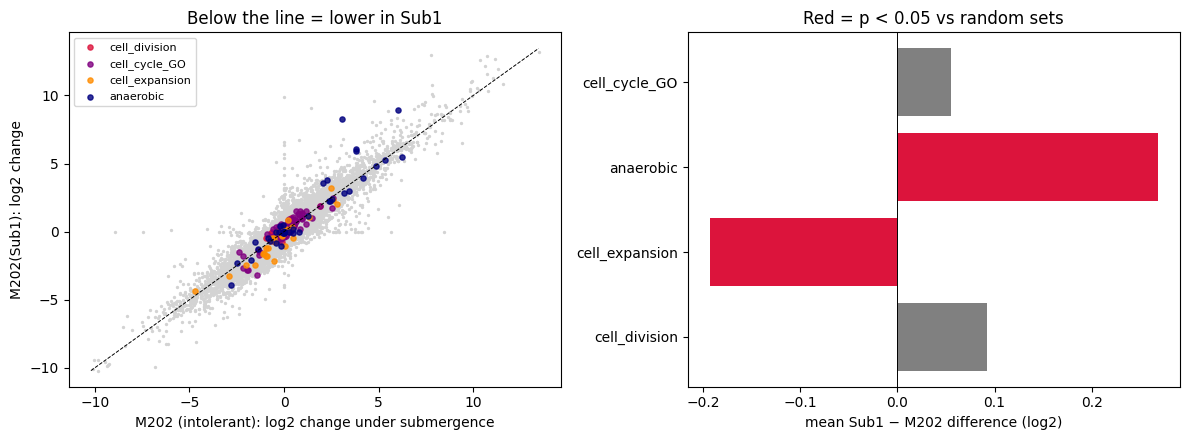

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for k, c in [('cell_division', 'crimson'), ('cell_cycle_GO', 'purple'), ('cell_expansion', 'darkorange'), ('anaerobic', 'navy')]:
    if len(GS.get(k, [])) >= 5:
        ax[0].scatter(resp['M202'][GS[k]], resp['Sub1'][GS[k]], s=14, c=c, label=k, alpha=0.8)
lim = [min(resp['M202'].min(), resp['Sub1'].min()), max(resp['M202'].max(), resp['Sub1'].max())]
ax[0].scatter(resp['M202'], resp['Sub1'], s=2, c='lightgray', zorder=0); ax[0].plot(lim, lim, 'k--', lw=0.7)
ax[0].set_xlabel('M202 (intolerant): log2 change under submergence'); ax[0].set_ylabel('M202(Sub1): log2 change')
ax[0].legend(fontsize=8); ax[0].set_title('Below the line = lower in Sub1')
sub = R[R.measure == 'Sub1 minus M202']
ax[1].barh(sub.set, sub.mean_log2, color=['crimson' if p < 0.05 else 'gray' for p in sub.p_two_sided])
ax[1].axvline(0, color='k', lw=0.7); ax[1].set_xlabel('mean Sub1 − M202 difference (log2)'); ax[1].set_title('Red = p < 0.05 vs random sets')
plt.tight_layout(); plt.savefig('rice_sub1_cell_division.png', dpi=150); plt.show()

## How to read the result
- **Label check FAIL** → the sample labels or array values are not what we think; stop.
- **Cell-expansion set lower in Sub1** confirms known biology (SUB1A restricts elongation) and shows the analysis works.
- **Cell-division set lower in Sub1 (p < 0.05)** → SUB1A's "wait underwater" strategy also pauses cell division: new and testable.
- Replicates are few, so treat any result as a lead to confirm in an RNA-seq dataset (e.g. GSE102494).

In [9]:
print('=' * 70); print('SEND THIS TO CLAUDE'); print('=' * 70); print('\n'.join(REPORT)); print('=' * 70)

SEND THIS TO CLAUDE
GSE18930: 8 samples, platforms: ['GPL2025']
design: M202/control: 2; M202/submerged: 2; Sub1/control: 2; Sub1/submerged: 2
submergence durations (days): [np.float64(1.0)]
probes: 57381; annotation columns: ['ID', 'GB_ACC', 'SPOT_ID', 'Species Scientific Name', 'Annotation Date', 'Sequence Type', 'Sequence Source', 'Representative Public ID', 'Target Description', 'Gene Title', 'Gene Symbol', 'ENTREZ_GENE_ID', 'RefSeq Transcript ID', 'Gene Ontology Biological Process', 'Gene Ontology Cellular Component', 'Gene Ontology Molecular Function']
genes after collapsing and filtering: 40461
gene set sizes: cell_division=45, cell_expansion=43, anaerobic=42, cell_cycle_GO=168
example annotation text: e. coli /gen=biob /db_xref=gb:j04423.1 /note=sif corresponding to nucleotides 2755-3052 of gb:j04423.1 /def=e.coli 7,8-d || e. coli /gen=biob /db_xref=gb:j04423.1 /note=sif corresponding to nucleotides 2032-2305 of gb:j04423.1 /def=e.coli 7,8-d || e. coli /gen=biob /db_xref=gb:j04